In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report


import tensorflow as tf

from src.datasets import create_datasets, class_names
from src.CNN_model_definitions import create_medium_model, create_small_model

2026-10-22 11:30:20.131652: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-22 11:30:20.147960: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-22 11:30:20.152914: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    device = "/GPU:0"
    print(f"Using GPU: {gpus[0]}")
else:
    device = "/CPU:0"
    print("No GPU detected. Using CPU.")


Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


I0000 00:00:1792668621.315178     556 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668621.323432     556 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668621.326139     556 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


### 01. Hyperparameters and data setup

In [3]:
IMG_SIZE = 64
CHANNELS = 3 
BATCH_SIZE = 32
LR = 0.001
EPOCHS = 20  # Set to a low number for convenience. Change as needed.

models_path = Path("models")

In [4]:
train_ds, val_ds, test_ds = create_datasets()

Found 4200 files belonging to 2 classes.


I0000 00:00:1792668621.569458     556 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668621.577187     556 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668621.579809     556 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792668621.731332     556 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Found 900 files belonging to 2 classes.
Found 900 files belonging to 2 classes.


Classes

### 02. Create CNN models

In [5]:
medium_model = create_medium_model()
small_model = create_small_model()

In [6]:
small_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), 
              metrics=["accuracy"])

print(small_model.summary())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 106,786 (417.13 KB)

 Trainable params: 106,306 (415.26 KB)

 Non-trainable params: 480 (1.88 KB)

None


In [7]:
medium_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), 
              metrics=["accuracy"])

print(medium_model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,490 (1.62 MB)

 Trainable params: 422,530 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

None


### 03. Small model training

In [8]:
# Create the ModelCheckpoint callback
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(filepath=models_path / "ai_capstone_keras_CNN_small.keras",
                                monitor='val_loss',      # or 'val_accuracy'
                                mode='min',              # 'min' for loss, 'max' for accuracy
                                save_best_only=True,
                                verbose=1
                               )

In [9]:
print(f"Training on : ==={device}=== with batch size: {BATCH_SIZE} & lr: {LR}")

history = small_model.fit(train_ds, 
                epochs= EPOCHS,
                validation_data=val_ds,
                callbacks=[checkpoint_cb],
                verbose=1
               )

Training on : ===/GPU:0=== with batch size: 32 & lr: 0.001
Epoch 1/20


I0000 00:00:1792668624.693018     637 service.cc:146] XLA service 0x7656c8017ed0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792668624.693063     637 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5


 23/132 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8319 - loss: 0.3919 

I0000 00:00:1792668627.961253     637 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9363 - loss: 0.1607
Epoch 1: val_loss improved from inf to 0.08461, saving model to models/ai_capstone_keras_CNN_small.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.9366 - loss: 0.1601 - val_accuracy: 0.9700 - val_loss: 0.0846
Epoch 2/20
124/132 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9847 - loss: 0.0498
Epoch 2: val_loss improved from 0.08461 to 0.02261, saving model to models/ai_capstone_keras_CNN_small.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9848 - loss: 0.0492 - val_accuracy: 0.9933 - val_loss: 0.0226
Epoch 3/20
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9878 - loss: 0.0375
Epoch 3: val_loss improved from 0.02261 to 0.00333, saving model to models/ai_capstone_keras_CNN_small.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9878 - loss: 0.0374 - val_accuracy: 1.0000 - val_loss: 0.0033
Epoch 4/20
126/132 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9876 - los

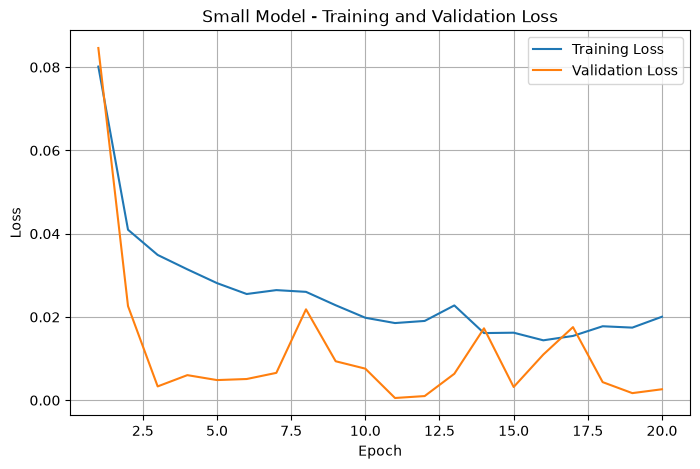

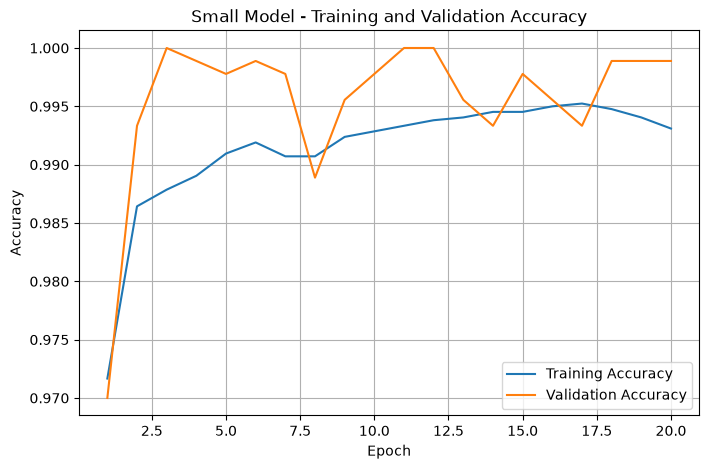

In [10]:
import matplotlib.pyplot as plt

# Extract history
hist = history.history
epochs = range(1, len(hist["loss"]) + 1)

# -------------------------
# Loss
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, hist["loss"], label="Training Loss")
plt.plot(epochs, hist["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Small Model - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


# -------------------------
# Accuracy
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, hist["accuracy"], label="Training Accuracy")
plt.plot(epochs, hist["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Small Model - Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

### 03. Meduim model training

In [11]:
# Create the ModelCheckpoint callback
checkpoint_cb2 = tf.keras.callbacks.ModelCheckpoint(filepath=models_path / "ai_capstone_keras_CNN_medium.keras",
                                monitor='val_loss',      # or 'val_accuracy'
                                mode='min',              # 'min' for loss, 'max' for accuracy
                                save_best_only=True,
                                verbose=1
                               )

In [12]:
history_meduim_training = medium_model.fit(train_ds, 
                epochs= EPOCHS,
                validation_data=val_ds,
                callbacks=[checkpoint_cb2],
                verbose=1
               )

Epoch 1/20
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9484 - loss: 0.1708
Epoch 1: val_loss improved from inf to 0.20846, saving model to models/ai_capstone_keras_CNN_medium.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - accuracy: 0.9486 - loss: 0.1701 - val_accuracy: 0.9233 - val_loss: 0.2085
Epoch 2/20
129/132 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9871 - loss: 0.0398
Epoch 2: val_loss improved from 0.20846 to 0.02339, saving model to models/ai_capstone_keras_CNN_medium.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9872 - loss: 0.0396 - val_accuracy: 0.9911 - val_loss: 0.0234
Epoch 3/20
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9840 - loss: 0.0418
Epoch 3: val_loss improved from 0.02339 to 0.00715, saving model to models/ai_capstone_keras_CNN_medium.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9840 - loss: 0.0418 - val_accuracy: 0.9978 - val_loss: 0.0072
Epoch 4/20
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - acc

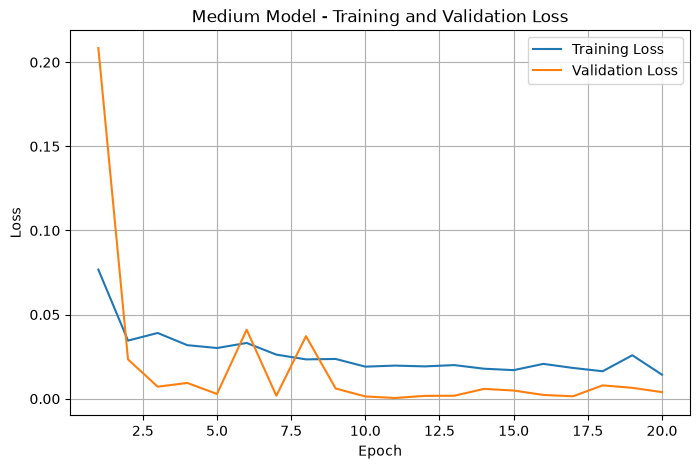

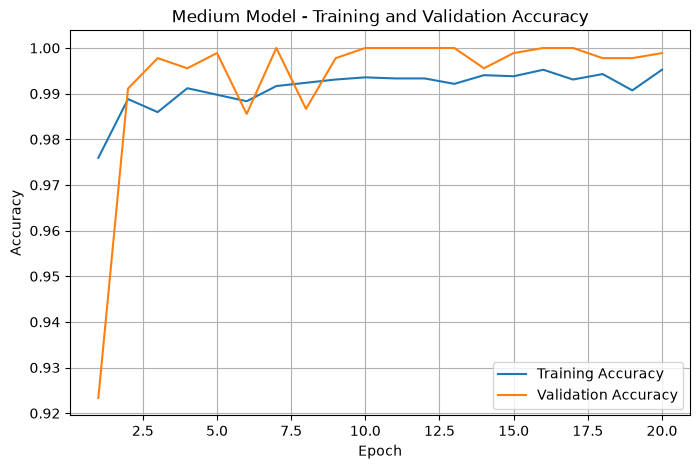

In [13]:
# Extract history
hist = history_meduim_training.history
epochs = range(1, len(hist["loss"]) + 1)

# -------------------------
# Loss
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, hist["loss"], label="Training Loss")
plt.plot(epochs, hist["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Medium Model - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


# -------------------------
# Accuracy
# -------------------------
plt.figure(figsize=(8, 5))

plt.plot(epochs, hist["accuracy"], label="Training Accuracy")
plt.plot(epochs, hist["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Medium Model - Training and Validation Accuracy")
plt.legend()
plt.grid(True)


### 04. Evaluate the two models

In [14]:
# load the best versions from the callbacks

models_path = Path("./models")

medium_model = tf.keras.models.load_model(
    models_path / "ai_capstone_keras_CNN_medium.keras"
)

small_model = tf.keras.models.load_model(
    models_path / "ai_capstone_keras_CNN_small.keras"
)


In [15]:
# Val Results
medium_results = medium_model.evaluate(val_ds, return_dict=True)
small_results = small_model.evaluate(val_ds, return_dict=True)

print("Medium model:", medium_results)
print("Small model:", small_results)

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 1.0000 - loss: 2.7447e-04
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 3.8735e-04
Medium model: {'accuracy': 1.0, 'loss': 0.00043755030492320657}
Small model: {'accuracy': 1.0, 'loss': 0.0005417118081822991}


In [16]:
# Test Results
medium_results = medium_model.evaluate(test_ds, return_dict=True)
small_results = small_model.evaluate(test_ds, return_dict=True)

print("Medium model:", medium_results)
print("Small model:", small_results)

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9991 - loss: 0.0102
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9919 - loss: 0.0145
Medium model: {'accuracy': 0.9977777600288391, 'loss': 0.017737863585352898}
Small model: {'accuracy': 0.992222249507904, 'loss': 0.018529091030359268}



Classification report: Medium model
                  precision    recall  f1-score   support

class_0_non_agri     0.9956    1.0000    0.9978       450
    class_1_agri     1.0000    0.9956    0.9978       450

        accuracy                         0.9978       900
       macro avg     0.9978    0.9978    0.9978       900
    weighted avg     0.9978    0.9978    0.9978       900


Classification report: Small model
                  precision    recall  f1-score   support

class_0_non_agri     0.9890    0.9956    0.9922       450
    class_1_agri     0.9955    0.9889    0.9922       450

        accuracy                         0.9922       900
       macro avg     0.9922    0.9922    0.9922       900
    weighted avg     0.9922    0.9922    0.9922       900



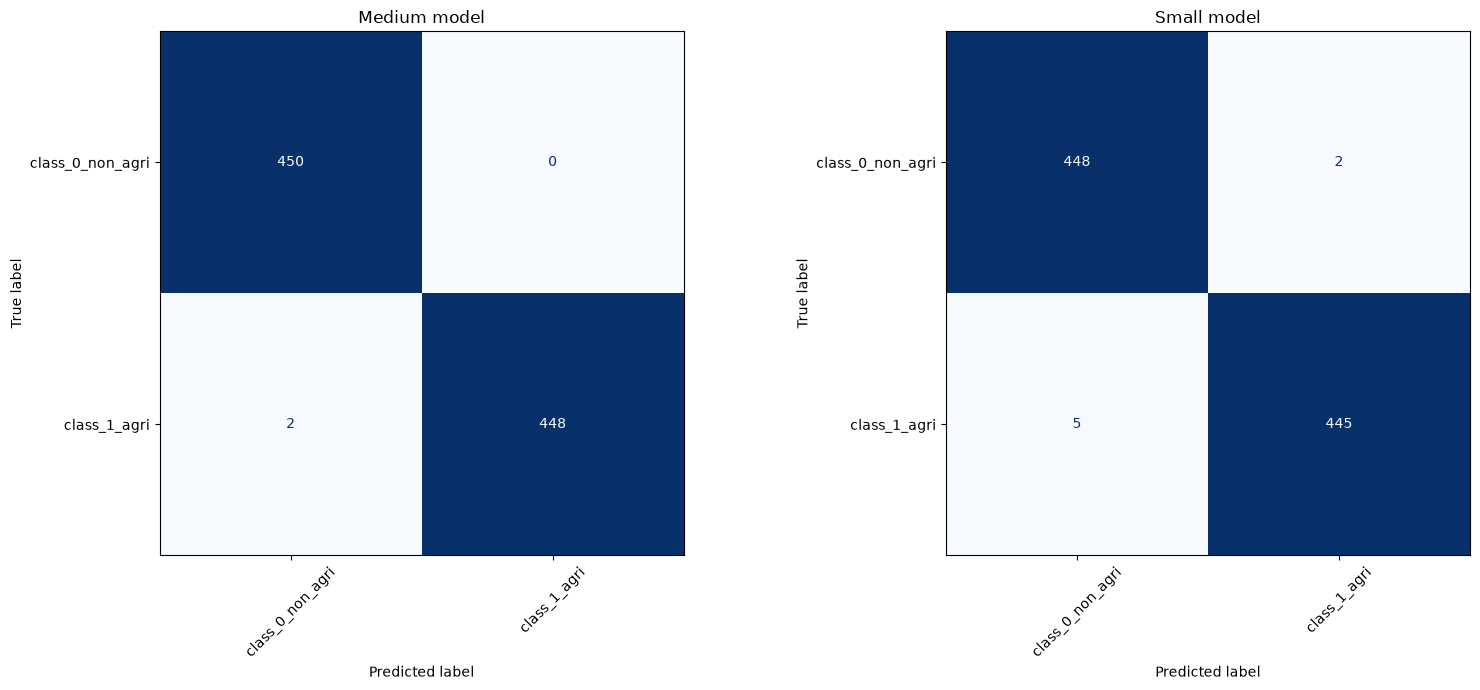

In [17]:
# Models to evaluate
models = {
    "Medium model": medium_model,
    "Small model": small_model,
}

# Extract true labels from the test dataset
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Handle one-hot encoded or integer labels
if y_true.ndim > 1 and y_true.shape[-1] > 1:
    y_true = np.argmax(y_true, axis=1)
else:
    y_true = y_true.reshape(-1).astype(int)


# Create side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (name, model) in zip(axes, models.items()):
    # Predict on the test set
    y_pred_probs = model.predict(test_ds, verbose=0)

    # Convert model outputs to predicted class indices
    if y_pred_probs.ndim > 1 and y_pred_probs.shape[-1] > 1:
        y_pred = np.argmax(y_pred_probs, axis=1)
    else:
        y_pred = (y_pred_probs.reshape(-1) >= 0.5).astype(int)

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(class_names))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)

    # Classification report
    print(f"\n{'=' * 60}")
    print(f"Classification report: {name}")
    print("=" * 60)

    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

plt.tight_layout()
plt.show()